# Section 8: Diffusion and Flow Matching

**Student:** WuShangxuan  
**GitHub username:** WuShangxuan0106  
**Date:** 2026-10-12

This notebook compares a small denoising diffusion model with a flow-matching
model on a two-dimensional synthetic distribution. The low-dimensional data
make the forward noising process, reverse denoising path, and learned vector
field directly visible. The same geometry can later be transferred to latent
representations of molecular or materials data.

## 0. Reproducibility and evaluation contract

Random seeds are fixed. The real data are split into train, validation, and
test. Models are trained on the train split, validation selects the checkpoint,
and the test split is used once for the final distribution comparison.

In [1]:
from __future__ import annotations

from copy import deepcopy
from pathlib import Path
import math
import random
import time

import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from torch import nn
import torch.nn.functional as F
from sklearn.datasets import make_moons
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

GLOBAL_SEED = 42
SPLIT_SEED = 42
DEVICE = torch.device("cpu")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)

def set_seed(seed: int = GLOBAL_SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(max(1, min(4, torch.get_num_threads())))

def regression_metrics(y_true, y_pred) -> dict[str, float]:
    mse = mean_squared_error(y_true, y_pred)
    return {
        "R2": float(r2_score(y_true, y_pred)),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "MSE": float(mse),
        "RMSE": float(np.sqrt(mse)),
    }

set_seed(GLOBAL_SEED)
print("numpy", np.__version__)
print("torch", torch.__version__)
print("device", DEVICE)

numpy 2.5.2
torch 2.13.0
device cpu


## 1. Real two-dimensional data

The data are two interleaving moons with Gaussian noise. This benchmark is
chosen because it has visible non-Gaussian geometry and a curved manifold while
remaining small enough to inspect every diffusion and flow trajectory.

In [2]:
X_all, _ = make_moons(n_samples=1400, noise=0.08, random_state=GLOBAL_SEED)
feature_names = ["x1", "x2"]

train_val_idx, test_idx = train_test_split(
    np.arange(len(X_all)),
    test_size=0.15,
    random_state=SPLIT_SEED,
)
train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.17647058823529413,
    random_state=SPLIT_SEED,
)

assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)

X_train_raw = X_all[train_idx].astype(np.float32)
X_val_raw = X_all[val_idx].astype(np.float32)
X_test_raw = X_all[test_idx].astype(np.float32)

scaler = StandardScaler().fit(X_train_raw)
X_train = scaler.transform(X_train_raw).astype(np.float32)
X_val = scaler.transform(X_val_raw).astype(np.float32)
X_test = scaler.transform(X_test_raw).astype(np.float32)

print("split sizes:", len(train_idx), len(val_idx), len(test_idx))
print("raw feature summary:")
print(pd.DataFrame(X_all, columns=feature_names).describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(4).to_string())
print("\nstandardized training summary:")
print(pd.DataFrame(X_train, columns=feature_names).describe().round(4).to_string())

for dim, name in enumerate(feature_names):
    q1, q3 = np.quantile(X_train[:, dim], [0.25, 0.75])
    iqr = q3 - q1
    outlier_count = int(np.sum((X_train[:, dim] < q1 - 1.5 * iqr) | (X_train[:, dim] > q3 + 1.5 * iqr)))
    print(f"{name}: IQR outliers in training split = {outlier_count}")

real_corr = pd.DataFrame(X_test, columns=feature_names).corr()
real_spearman = pd.DataFrame(X_test, columns=feature_names).corr(method="spearman")
print("\nReal test Pearson correlation:")
print(real_corr.round(4).to_string())
print("\nReal test Spearman correlation:")
print(real_spearman.round(4).to_string())

pca_real = PCA(n_components=2, random_state=GLOBAL_SEED).fit(X_train)
P_train = pca_real.transform(X_train)
P_val = pca_real.transform(X_val)
P_test = pca_real.transform(X_test)
print("\nPCA explained variance ratio fitted on training data:", pca_real.explained_variance_ratio_.round(4))

split sizes: 980 210 210
raw feature summary:
              x1         x2
count  1400.0000  1400.0000
mean      0.5018     0.2540
std       0.8723     0.4984
min      -1.1196    -0.6919
25%      -0.0505    -0.2114
50%       0.4949     0.2461
75%       1.0891     0.7012
95%       1.9604     1.0066
99%       2.0655     1.0979
max       2.2044     1.1870

standardized training summary:
             x1        x2
count  980.0000  980.0000
mean     0.0000   -0.0000
std      1.0005    1.0005
min     -1.8407   -1.9096
25%     -0.6388   -0.9299
50%     -0.0019   -0.0022
75%      0.6633    0.9040
max      1.9580    1.8683
x1: IQR outliers in training split = 0
x2: IQR outliers in training split = 0

Real test Pearson correlation:
        x1      x2
x1  1.0000 -0.4305
x2 -0.4305  1.0000

Real test Spearman correlation:
       x1     x2
x1  1.000 -0.468
x2 -0.468  1.000

PCA explained variance ratio fitted on training data: [0.7164 0.2836]


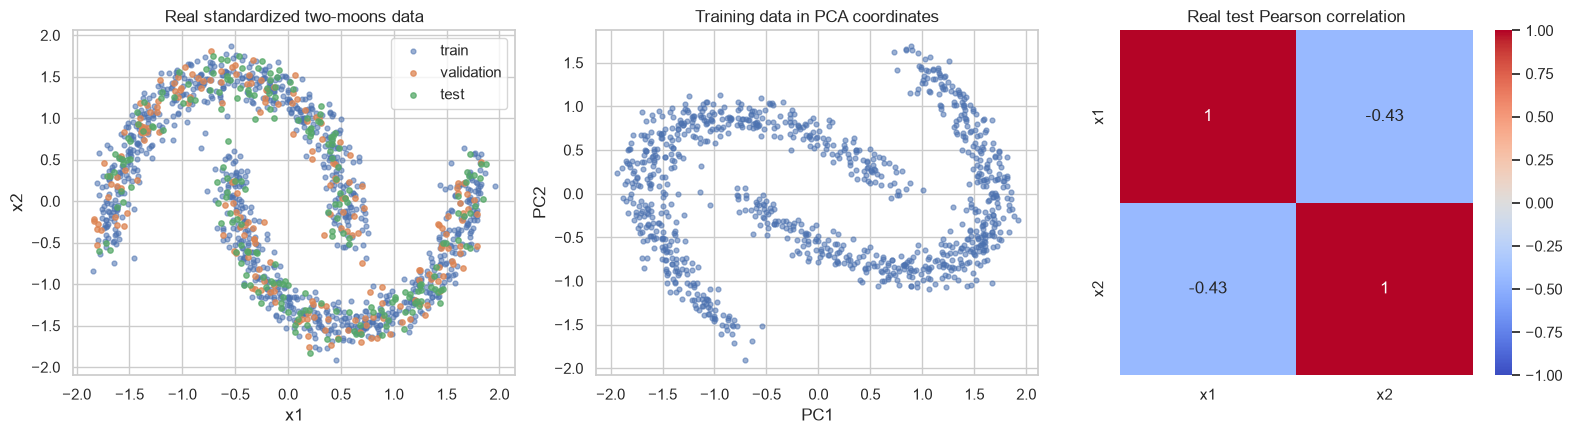

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(X_train[:, 0], X_train[:, 1], s=12, alpha=0.55, label="train")
axes[0].scatter(X_val[:, 0], X_val[:, 1], s=15, alpha=0.75, label="validation")
axes[0].scatter(X_test[:, 0], X_test[:, 1], s=15, alpha=0.75, label="test")
axes[0].set(title="Real standardized two-moons data", xlabel="x1", ylabel="x2")
axes[0].legend()

axes[1].scatter(P_train[:, 0], P_train[:, 1], s=12, alpha=0.55)
axes[1].set(title="Training data in PCA coordinates", xlabel="PC1", ylabel="PC2")

sns.heatmap(real_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=axes[2])
axes[2].set_title("Real test Pearson correlation")
plt.tight_layout()
plt.show()

## 2. Diffusion model

The forward process gradually adds Gaussian noise:

`x_t = sqrt(alpha_bar_t) x_0 + sqrt(1 - alpha_bar_t) epsilon`.

The model is trained to predict `epsilon` from `(x_t, t)`. Sampling starts from
Gaussian noise and runs the reverse process from `t = T - 1` down to `t = 0`.

In [4]:
T = 100
beta_start = 1e-4
beta_end = 2e-2
betas = torch.linspace(beta_start, beta_end, T, device=DEVICE)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)

class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim: int):
        super().__init__()
        if dim % 2 != 0:
            raise ValueError("time embedding dimension must be even")
        self.dim = dim

    def forward(self, t_scaled):
        half = self.dim // 2
        frequencies = torch.exp(
            -math.log(10_000) * torch.arange(half, device=t_scaled.device).float() / max(1, half - 1)
        )
        angles = t_scaled[:, None] * frequencies[None, :]
        return torch.cat([angles.sin(), angles.cos()], dim=-1)


class ConditionalVectorNet(nn.Module):
    def __init__(self, data_dim: int = 2, hidden_dim: int = 128, time_dim: int = 32):
        super().__init__()
        self.time_embedding = SinusoidalTimeEmbedding(time_dim)
        self.network = nn.Sequential(
            nn.Linear(data_dim + time_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, data_dim),
        )

    def forward(self, x, t_scaled):
        time_features = self.time_embedding(t_scaled)
        return self.network(torch.cat([x, time_features], dim=-1))


def diffusion_training_batch(x0, t):
    noise = torch.randn_like(x0)
    noisy = sqrt_alpha_bars[t, None] * x0 + sqrt_one_minus_alpha_bars[t, None] * noise
    return noisy, noise


def train_diffusion(
    model,
    train_data: np.ndarray,
    val_data: np.ndarray,
    epochs: int = 700,
    batch_size: int = 256,
):
    x_train = torch.from_numpy(train_data).to(DEVICE)
    x_val = torch.from_numpy(val_data).to(DEVICE)
    generator = torch.Generator().manual_seed(GLOBAL_SEED + 11)
    fixed_val_t = torch.randint(T, (len(x_val),), generator=generator)
    fixed_val_noise = torch.randn(x_val.shape, generator=generator)
    fixed_val_noisy = (
        sqrt_alpha_bars[fixed_val_t, None] * x_val
        + sqrt_one_minus_alpha_bars[fixed_val_t, None] * fixed_val_noise
    )

    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-5)
    history = []
    best_state = deepcopy(model.state_dict())
    best_val_loss = float("inf")
    best_epoch = -1
    start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        permutation = torch.randperm(len(x_train))
        running_loss = 0.0
        seen = 0
        for start_index in range(0, len(x_train), batch_size):
            batch_indices = permutation[start_index:start_index + batch_size]
            x0 = x_train[batch_indices]
            t = torch.randint(T, (len(x0),), device=DEVICE)
            noisy, noise = diffusion_training_batch(x0, t)
            prediction = model(noisy, t.float() / T)
            loss = F.mse_loss(prediction, noise)

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            running_loss += loss.item() * len(x0)
            seen += len(x0)

        model.eval()
        with torch.no_grad():
            val_prediction = model(fixed_val_noisy, fixed_val_t.float() / T)
            val_loss = F.mse_loss(val_prediction, fixed_val_noise).item()
        history.append({
            "epoch": epoch,
            "train_loss": running_loss / seen,
            "validation_loss": val_loss,
        })
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    elapsed = time.perf_counter() - start
    print(f"diffusion: best epoch={best_epoch}, seconds={elapsed:.2f}, best validation loss={best_val_loss:.5f}")
    return model, pd.DataFrame(history), best_epoch, elapsed

set_seed(GLOBAL_SEED)
diffusion_model = ConditionalVectorNet().to(DEVICE)
diffusion_model, diffusion_history, diffusion_best_epoch, diffusion_seconds = train_diffusion(
    diffusion_model,
    X_train,
    X_val,
)
diffusion_parameters = sum(p.numel() for p in diffusion_model.parameters() if p.requires_grad)
print("diffusion parameters:", diffusion_parameters)

diffusion: best epoch=686, seconds=1.43, best validation loss=0.68408
diffusion parameters: 21250


## 3. Flow matching

Flow matching learns a velocity field that transports Gaussian noise to data.
For the straight probability path with source noise `z` and data `x_0`:

`x_t = (1 - t) z + t x_0`, and the target velocity is `v = x_0 - z`.

Sampling solves the ordinary differential equation `dx/dt = v_theta(x_t, t)`
from `t = 0` to `t = 1` with Euler integration.

In [5]:
def train_flow_matching(
    model,
    train_data: np.ndarray,
    val_data: np.ndarray,
    epochs: int = 700,
    batch_size: int = 256,
):
    x_train = torch.from_numpy(train_data).to(DEVICE)
    x_val = torch.from_numpy(val_data).to(DEVICE)
    generator = torch.Generator().manual_seed(GLOBAL_SEED + 23)
    fixed_val_t = torch.rand((len(x_val),), generator=generator)
    fixed_val_noise = torch.randn(x_val.shape, generator=generator)
    fixed_val_path = (1.0 - fixed_val_t[:, None]) * fixed_val_noise + fixed_val_t[:, None] * x_val
    fixed_val_target = x_val - fixed_val_noise

    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-5)
    history = []
    best_state = deepcopy(model.state_dict())
    best_val_loss = float("inf")
    best_epoch = -1
    start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        permutation = torch.randperm(len(x_train))
        running_loss = 0.0
        seen = 0
        for start_index in range(0, len(x_train), batch_size):
            batch_indices = permutation[start_index:start_index + batch_size]
            x0 = x_train[batch_indices]
            noise = torch.randn_like(x0)
            t = torch.rand((len(x0), 1), device=DEVICE)
            path_point = (1.0 - t) * noise + t * x0
            target_velocity = x0 - noise
            prediction = model(path_point, t.squeeze(-1))
            loss = F.mse_loss(prediction, target_velocity)

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            running_loss += loss.item() * len(x0)
            seen += len(x0)

        model.eval()
        with torch.no_grad():
            val_prediction = model(fixed_val_path, fixed_val_t)
            val_loss = F.mse_loss(val_prediction, fixed_val_target).item()
        history.append({
            "epoch": epoch,
            "train_loss": running_loss / seen,
            "validation_loss": val_loss,
        })
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    elapsed = time.perf_counter() - start
    print(f"flow matching: best epoch={best_epoch}, seconds={elapsed:.2f}, best validation loss={best_val_loss:.5f}")
    return model, pd.DataFrame(history), best_epoch, elapsed

set_seed(GLOBAL_SEED + 1)
flow_model = ConditionalVectorNet().to(DEVICE)
flow_model, flow_history, flow_best_epoch, flow_seconds = train_flow_matching(
    flow_model,
    X_train,
    X_val,
)
flow_parameters = sum(p.numel() for p in flow_model.parameters() if p.requires_grad)
print("flow-matching parameters:", flow_parameters)

flow matching: best epoch=662, seconds=1.41, best validation loss=1.43985
flow-matching parameters: 21250


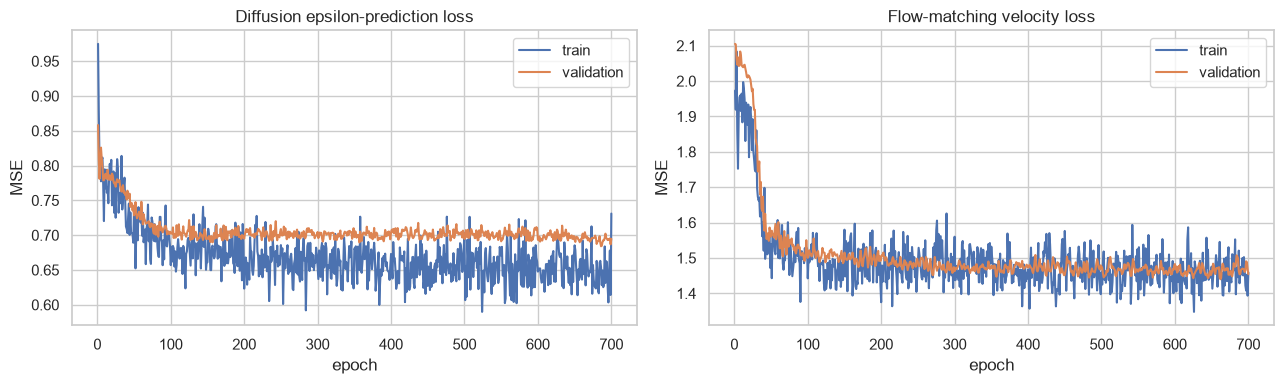

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(diffusion_history["epoch"], diffusion_history["train_loss"], label="train")
axes[0].plot(diffusion_history["epoch"], diffusion_history["validation_loss"], label="validation")
axes[0].set(title="Diffusion epsilon-prediction loss", xlabel="epoch", ylabel="MSE")
axes[0].legend()

axes[1].plot(flow_history["epoch"], flow_history["train_loss"], label="train")
axes[1].plot(flow_history["epoch"], flow_history["validation_loss"], label="validation")
axes[1].set(title="Flow-matching velocity loss", xlabel="epoch", ylabel="MSE")
axes[1].legend()
plt.tight_layout()
plt.show()

## 4. Forward diffusion and reverse denoising

The forward panels show real points noised with the diffusion schedule. The
reverse panels show generated samples after successive denoising steps. The
reverse process starts as a broad Gaussian cloud and progressively creates the
two curved modes.

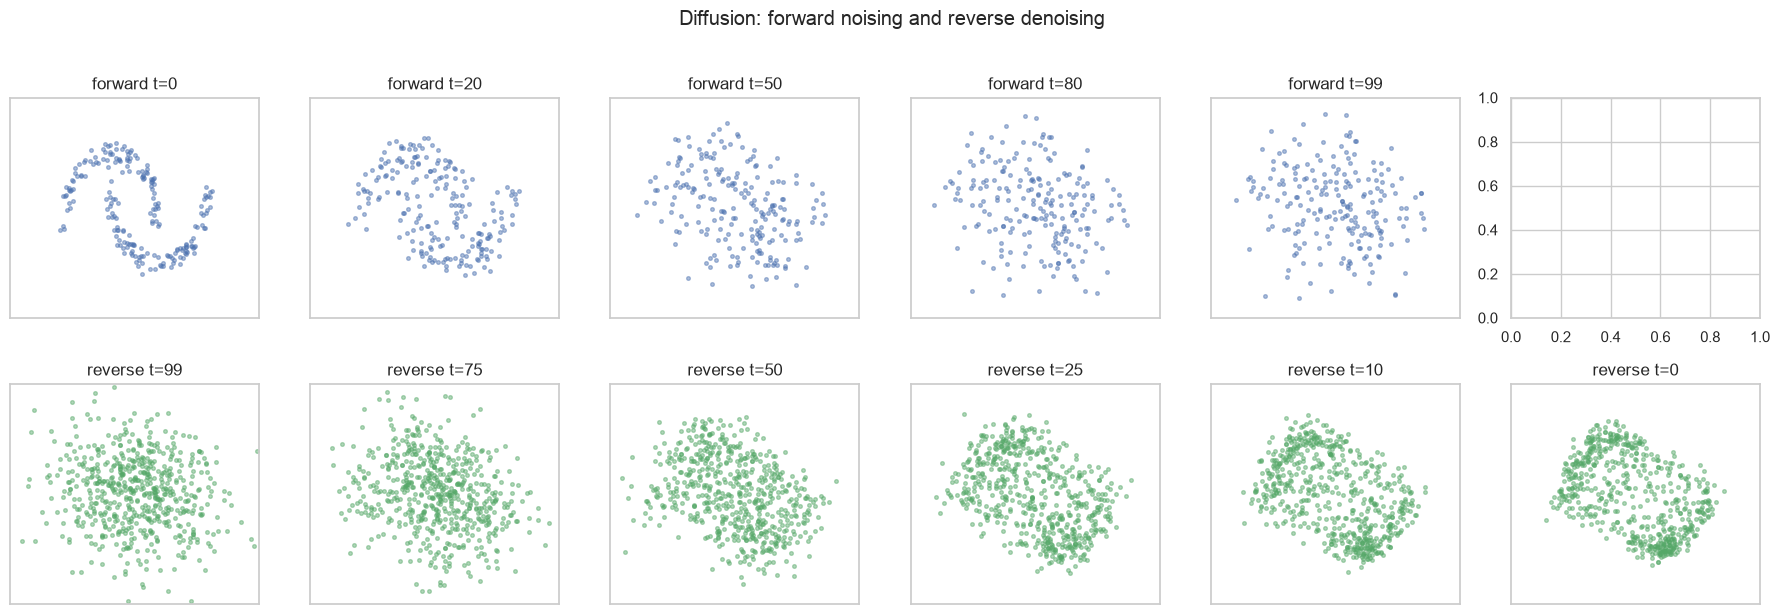

In [7]:
def diffusion_forward_snapshots(x0: torch.Tensor, timesteps):
    noise = torch.randn_like(x0)
    snapshots = {}
    for t in timesteps:
        noisy = sqrt_alpha_bars[t] * x0 + sqrt_one_minus_alpha_bars[t] * noise
        snapshots[t] = noisy.detach().cpu().numpy()
    return snapshots


@torch.no_grad()
def diffusion_reverse_snapshots(model, n_samples: int, capture_steps):
    model.eval()
    x = torch.randn(n_samples, 2, device=DEVICE)
    capture_steps = list(capture_steps)
    snapshots = {T: x.detach().cpu().numpy()}
    for t in reversed(range(T)):
        if t in capture_steps:
            snapshots[t] = x.detach().cpu().numpy()
        t_tensor = torch.full((len(x),), t, device=DEVICE)
        eps_prediction = model(x, t_tensor.float() / T)
        beta_t = betas[t]
        alpha_t = alphas[t]
        alpha_bar_t = alpha_bars[t]
        mean = (x - beta_t / torch.sqrt(1.0 - alpha_bar_t) * eps_prediction) / torch.sqrt(alpha_t)
        if t > 0:
            posterior_variance = beta_t * (1.0 - alpha_bars[t - 1]) / (1.0 - alpha_bar_t)
            x = mean + torch.sqrt(posterior_variance) * torch.randn_like(x)
        else:
            x = mean
    snapshots[0] = x.detach().cpu().numpy()
    return snapshots

forward_steps = [0, 20, 50, 80, 99]
reverse_steps = [99, 75, 50, 25, 10, 0]
forward_snapshots = diffusion_forward_snapshots(torch.from_numpy(X_test[:600]), forward_steps)
reverse_snapshots = diffusion_reverse_snapshots(diffusion_model, 600, reverse_steps)

fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for ax, t in zip(axes[0], forward_steps):
    points = forward_snapshots[t]
    ax.scatter(points[:, 0], points[:, 1], s=7, alpha=0.45, color="#4c72b0")
    ax.set(title=f"forward t={t}", xlim=(-3, 3), ylim=(-3, 3))
    ax.set_xticks([])
    ax.set_yticks([])
for ax, t in zip(axes[1], reverse_steps):
    points = reverse_snapshots[t]
    ax.scatter(points[:, 0], points[:, 1], s=7, alpha=0.45, color="#55a868")
    ax.set(title=f"reverse t={t}", xlim=(-3, 3), ylim=(-3, 3))
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle("Diffusion: forward noising and reverse denoising", y=1.02)
plt.tight_layout()
plt.show()

## 5. Flow-matching trajectories

The flow model transports noise to data along a learned vector field. The panels
show the sample cloud at increasing ODE time. A second plot follows several
individual particles to make the trajectory shape visible.

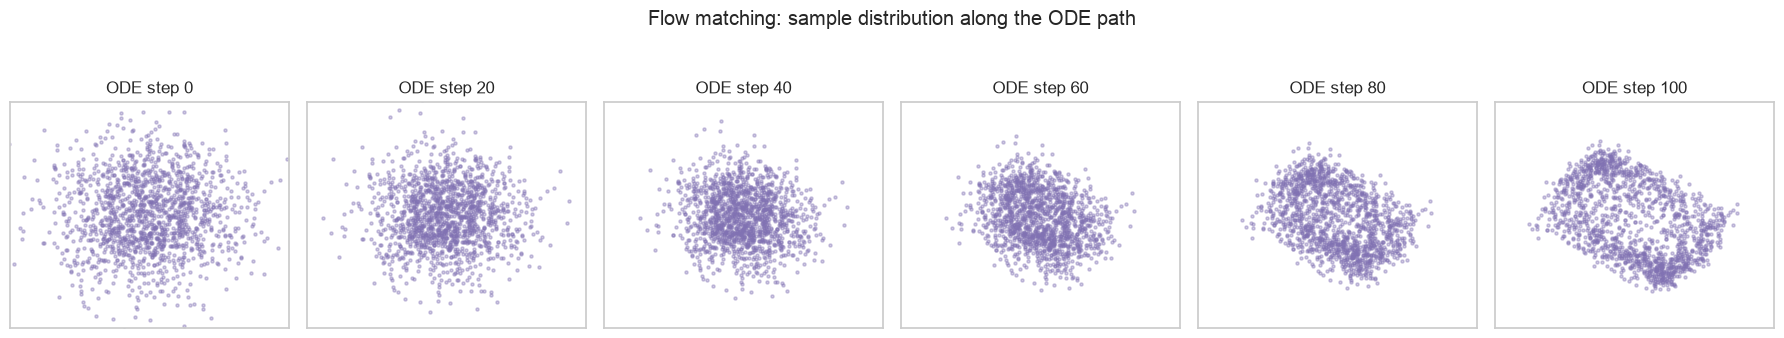

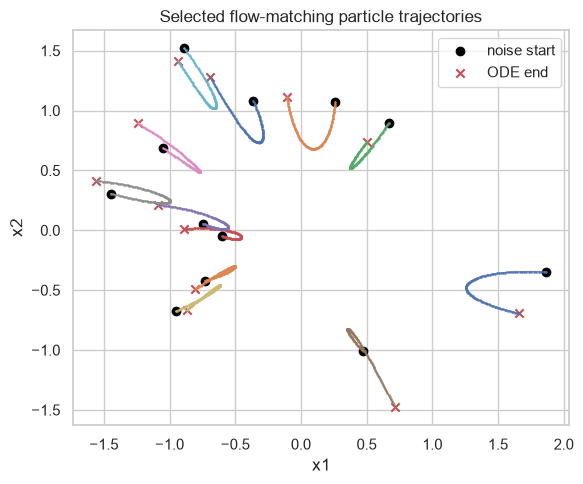

In [8]:
@torch.no_grad()
def sample_flow_matching(model, n_samples: int, n_steps: int = 100, capture_indices=None):
    model.eval()
    capture_indices = set([] if capture_indices is None else capture_indices)
    x = torch.randn(n_samples, 2, device=DEVICE)
    trajectories = []
    snapshots = {0: x.detach().cpu().numpy()}
    dt = 1.0 / n_steps
    for step in range(n_steps):
        t = step / n_steps
        t_tensor = torch.full((len(x),), t, device=DEVICE)
        velocity = model(x, t_tensor)
        x = x + dt * velocity
        if step + 1 in capture_indices:
            snapshots[step + 1] = x.detach().cpu().numpy()
    snapshots[n_steps] = x.detach().cpu().numpy()
    return snapshots, x.detach().cpu().numpy()

trace_count = 12
flow_trace_indices = np.linspace(0, 99, trace_count, dtype=int)
flow_snapshots, flow_generated = sample_flow_matching(
    flow_model,
    1500,
    n_steps=100,
    capture_indices=[0, 20, 40, 60, 80, 100],
)

fig, axes = plt.subplots(1, 6, figsize=(18, 3.2))
for ax, step in zip(axes, [0, 20, 40, 60, 80, 100]):
    points = flow_snapshots[step]
    ax.scatter(points[:, 0], points[:, 1], s=5, alpha=0.38, color="#8172b3")
    ax.set(title=f"ODE step {step}", xlim=(-3, 3), ylim=(-3, 3))
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle("Flow matching: sample distribution along the ODE path", y=1.05)
plt.tight_layout()
plt.show()

@torch.no_grad()
def flow_particle_trajectory(model, n_samples: int, n_steps: int):
    x = torch.randn(n_samples, 2, device=DEVICE)
    trajectory = [x.detach().cpu().numpy()]
    dt = 1.0 / n_steps
    for step in range(n_steps):
        t = step / n_steps
        x = x + dt * model(x, torch.full((len(x),), t, device=DEVICE))
        trajectory.append(x.detach().cpu().numpy())
    return np.stack(trajectory, axis=0)

particle_paths = flow_particle_trajectory(flow_model, trace_count, 100)
fig, ax = plt.subplots(figsize=(6, 5))
for particle in range(trace_count):
    ax.plot(
        particle_paths[:, particle, 0],
        particle_paths[:, particle, 1],
        marker=".",
        markersize=2,
        linewidth=1,
        alpha=0.75,
    )
ax.scatter(particle_paths[0, :, 0], particle_paths[0, :, 1], marker="o", color="black", label="noise start")
ax.scatter(particle_paths[-1, :, 0], particle_paths[-1, :, 1], marker="x", color="#c44e52", label="ODE end")
ax.set(title="Selected flow-matching particle trajectories", xlabel="x1", ylabel="x2")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Generated distribution comparison

Diffusion and flow matching are sampled from the same fixed number of Gaussian
seeds. Quality is evaluated against the held-out real test split using summary
statistics, per-coordinate Wasserstein distance, energy distance, covariance
difference, box plots, correlations, and PCA.

In [9]:
@torch.no_grad()
def sample_diffusion(model, n_samples: int):
    model.eval()
    x = torch.randn(n_samples, 2, device=DEVICE)
    for t in reversed(range(T)):
        t_tensor = torch.full((len(x),), t, device=DEVICE)
        eps_prediction = model(x, t_tensor.float() / T)
        beta_t = betas[t]
        alpha_t = alphas[t]
        alpha_bar_t = alpha_bars[t]
        mean = (x - beta_t / torch.sqrt(1.0 - alpha_bar_t) * eps_prediction) / torch.sqrt(alpha_t)
        if t > 0:
            posterior_variance = beta_t * (1.0 - alpha_bars[t - 1]) / (1.0 - alpha_bar_t)
            x = mean + torch.sqrt(posterior_variance) * torch.randn_like(x)
        else:
            x = mean
    return x.detach().cpu().numpy()

set_seed(GLOBAL_SEED + 101)
diffusion_generated = sample_diffusion(diffusion_model, 1500)

def radius(points):
    return np.sqrt(np.sum(np.asarray(points) ** 2, axis=1))

def distribution_summary(points, label):
    points = np.asarray(points)
    rows = []
    for dim, name in enumerate(feature_names):
        values = points[:, dim]
        rows.append({
            "sample": label,
            "variable": name,
            "mean": values.mean(),
            "std": values.std(ddof=1),
            "median": np.median(values),
            "q25": np.quantile(values, 0.25),
            "q75": np.quantile(values, 0.75),
            "skew": pd.Series(values).skew(),
        })
    values = radius(points)
    rows.append({
        "sample": label,
        "variable": "radius",
        "mean": values.mean(),
        "std": values.std(ddof=1),
        "median": np.median(values),
        "q25": np.quantile(values, 0.25),
        "q75": np.quantile(values, 0.75),
        "skew": pd.Series(values).skew(),
    })
    return pd.DataFrame(rows)

summary_table = pd.concat([
    distribution_summary(X_test, "real test"),
    distribution_summary(diffusion_generated, "diffusion"),
    distribution_summary(flow_generated, "flow matching"),
], ignore_index=True)
print(summary_table.round(4).to_string(index=False))

def wasserstein_1d(a, b, n_quantiles=200):
    quantiles = np.linspace(0, 1, n_quantiles)
    return float(np.mean(np.abs(np.quantile(a, quantiles) - np.quantile(b, quantiles))))

def energy_distance(a, b):
    a_tensor = torch.from_numpy(np.asarray(a, dtype=np.float32))
    b_tensor = torch.from_numpy(np.asarray(b, dtype=np.float32))
    ab = torch.cdist(a_tensor, b_tensor).mean().item()
    aa = torch.cdist(a_tensor, a_tensor).mean().item()
    bb = torch.cdist(b_tensor, b_tensor).mean().item()
    return float(2 * ab - aa - bb)

def distribution_distance_table(real, generated, label):
    rows = []
    for dim, name in enumerate(feature_names):
        rows.append({
            "generated sample": label,
            "measure": f"Wasserstein {name}",
            "value": wasserstein_1d(real[:, dim], generated[:, dim]),
        })
    rows.append({
        "generated sample": label,
        "measure": "Wasserstein radius",
        "value": wasserstein_1d(radius(real), radius(generated)),
    })
    rows.append({
        "generated sample": label,
        "measure": "energy distance",
        "value": energy_distance(real, generated),
    })
    rows.append({
        "generated sample": label,
        "measure": "mean difference norm",
        "value": float(np.linalg.norm(real.mean(axis=0) - generated.mean(axis=0))),
    })
    rows.append({
        "generated sample": label,
        "measure": "covariance Frobenius difference",
        "value": float(np.linalg.norm(np.cov(real, rowvar=False) - np.cov(generated, rowvar=False))),
    })
    return pd.DataFrame(rows)

distance_table = pd.concat([
    distribution_distance_table(X_test, diffusion_generated, "diffusion"),
    distribution_distance_table(X_test, flow_generated, "flow matching"),
], ignore_index=True)
print("\nDistribution distances (lower is closer):")
print(distance_table.pivot(index="measure", columns="generated sample", values="value").round(4).to_string())

       sample variable    mean    std  median     q25    q75    skew
    real test       x1  0.0783 0.9467  0.0318 -0.5418 0.6725  0.0033
    real test       x2 -0.0173 1.0266  0.0086 -1.0302 0.8789  0.0401
    real test   radius  1.3250 0.4388  1.4999  0.9489 1.6982 -0.5805
    diffusion       x1 -0.0793 1.0045 -0.0903 -0.9233 0.7434  0.0647
    diffusion       x2 -0.0356 0.9894 -0.0577 -0.9202 0.8099  0.0674
    diffusion   radius  1.3547 0.3987  1.4430  1.0984 1.6630 -0.7259
flow matching       x1 -0.0114 0.9471 -0.0222 -0.7676 0.7385  0.0408
flow matching       x2 -0.1431 0.9880 -0.1966 -1.0287 0.7383  0.1056
flow matching   radius  1.3142 0.4067  1.3699  1.0498 1.6261 -0.4725

Distribution distances (lower is closer):
generated sample                 diffusion  flow matching
measure                                                  
Wasserstein radius                  0.0720         0.0933
Wasserstein x1                      0.1724         0.1281
Wasserstein x2                     

## 7. Predictive-component diagnostics

Unconditional generation is judged mainly by distributional similarity. The
trained networks still contain predictive components: diffusion predicts noise
and flow matching predicts velocity. Those predictions can be scored with the
Section 3 regression metrics R2, MAE, MSE, and RMSE on held-out real data. These
numbers describe the auxiliary prediction task, not the quality of generated
samples by themselves.

In [10]:
diffusion_model.eval()
flow_model.eval()
metrics_rows = []

with torch.no_grad():
    for label, timestep in [("diffusion t=25", 25), ("diffusion t=50", 50), ("diffusion t=75", 75)]:
        x0 = torch.from_numpy(X_test).to(DEVICE)
        generator = torch.Generator().manual_seed(GLOBAL_SEED + timestep)
        noise = torch.randn(x0.shape, generator=generator)
        x_t = sqrt_alpha_bars[timestep] * x0 + sqrt_one_minus_alpha_bars[timestep] * noise
        prediction = diffusion_model(x_t, torch.full((len(x_t),), timestep / T, device=DEVICE))
        metrics = regression_metrics(noise.numpy(), prediction.cpu().numpy())
        metrics_rows.append({"prediction task": label, **metrics})

    x0 = torch.from_numpy(X_test).to(DEVICE)
    generator = torch.Generator().manual_seed(GLOBAL_SEED + 404)
    noise = torch.randn(x0.shape, generator=generator)
    t = torch.rand((len(x0), 1), generator=generator)
    path_point = (1.0 - t) * noise + t * x0
    target_velocity = x0 - noise
    prediction = flow_model(path_point, t.squeeze(-1))
    metrics_rows.append({
        "prediction task": "flow-matching velocity",
        **regression_metrics(target_velocity.numpy(), prediction.cpu().numpy()),
    })

predictive_metrics = pd.DataFrame(metrics_rows).set_index("prediction task")
print(predictive_metrics.round(4).to_string())
print("\nNote: R2 for random noise or velocity targets is a diagnostic only and can be near zero or negative.")

                            R2     MAE     MSE    RMSE
prediction task                                       
diffusion t=25          0.2365  0.6792  0.7449  0.8631
diffusion t=50          0.2944  0.6400  0.6697  0.8184
diffusion t=75          0.5126  0.5456  0.4673  0.6836
flow-matching velocity  0.1979  1.0033  1.5269  1.2357

Note: R2 for random noise or velocity targets is a diagnostic only and can be near zero or negative.


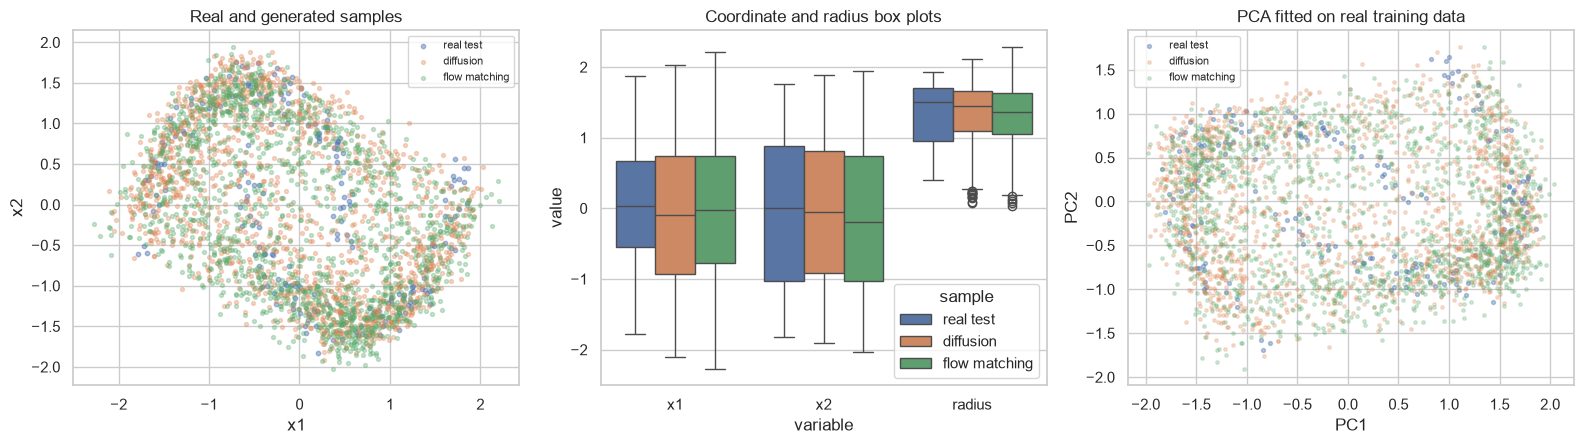

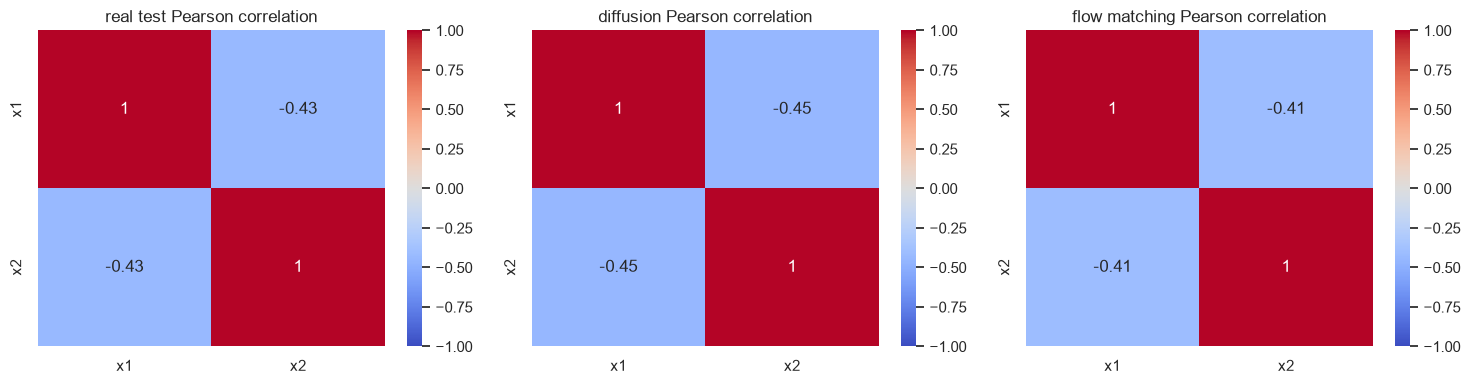

Real test PCA explained variance ratio: [0.7164 0.2836]
diffusion variance in real-PC coordinates: [1.4389 0.5489]
diffusion Pearson x1/x2 correlation: (1500, 2) 0.017
flow matching variance in real-PC coordinates: [1.3203 0.5529]
flow matching Pearson x1/x2 correlation: (1500, 2) -0.0463


In [11]:
generated_by_name = {
    "diffusion": diffusion_generated,
    "flow matching": flow_generated,
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
axes[0].scatter(X_test[:, 0], X_test[:, 1], s=10, alpha=0.45, label="real test")
axes[0].scatter(diffusion_generated[:, 0], diffusion_generated[:, 1], s=8, alpha=0.32, label="diffusion")
axes[0].scatter(flow_generated[:, 0], flow_generated[:, 1], s=8, alpha=0.32, label="flow matching")
axes[0].set(title="Real and generated samples", xlabel="x1", ylabel="x2")
axes[0].legend(fontsize=8)

box_rows = []
for label, points in [("real test", X_test), *generated_by_name.items()]:
    for dim, name in enumerate(feature_names):
        for value in points[:, dim]:
            box_rows.append({"sample": label, "variable": name, "value": value})
    for value in radius(points):
        box_rows.append({"sample": label, "variable": "radius", "value": value})
box_frame = pd.DataFrame(box_rows)
sns.boxplot(data=box_frame, x="variable", y="value", hue="sample", ax=axes[1])
axes[1].set(title="Coordinate and radius box plots")

P_generated = {label: pca_real.transform(points) for label, points in generated_by_name.items()}
axes[2].scatter(P_test[:, 0], P_test[:, 1], s=8, alpha=0.40, label="real test")
for label, points in P_generated.items():
    axes[2].scatter(points[:, 0], points[:, 1], s=6, alpha=0.25, label=label)
axes[2].set(title="PCA fitted on real training data", xlabel="PC1", ylabel="PC2")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (label, points) in zip(axes, [("real test", X_test), *generated_by_name.items()]):
    corr = pd.DataFrame(points, columns=feature_names).corr()
    sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"{label} Pearson correlation")
plt.tight_layout()
plt.show()

print("Real test PCA explained variance ratio:", pca_real.explained_variance_ratio_.round(4))
for label, points in P_generated.items():
    explained = points.var(axis=0, ddof=1)
    print(f"{label} variance in real-PC coordinates:", explained.round(4))
    print(f"{label} Pearson x1/x2 correlation:", points.shape, round(float(np.corrcoef(points[:, 0], points[:, 1])[0, 1]), 4))

## 8. Critical answers

**1. What is the diffusion training target and sampling process?**

Diffusion training selects a random timestep, samples Gaussian noise, constructs
`x_t` with the forward schedule, and trains the network to predict the noise
that was added. Sampling starts from Gaussian noise and runs the reverse
transition from high noise to low noise. At each step the model predicts noise,
which is converted into an estimate of the previous latent state. A small
posterior noise term is added for every step except the final one.

**2. What is the flow-matching training target and sampling process?**

Flow matching uses the straight path
`x_t = (1 - t) noise + t data` for `0 <= t <= 1`. The network is trained to
predict the velocity `data - noise` along that path. Sampling integrates the
learned velocity field with an ODE solver. This notebook uses Euler steps from
`t = 0` to `t = 1`, starting from Gaussian noise.

**3. How close are the generated distributions?**

The comparison reports coordinate and radius summaries, 1D Wasserstein
distances, energy distance, mean difference, covariance difference, box plots,
correlations, and PCA coordinates. Both generators approximately recover the
two curved modes, but slight mode thickness, tail behavior, and correlation
differences remain. The number of samples is finite, so visual scatter plots
should not be over-interpreted.

**4. Do Section 3 regression metrics apply to generation?**

Not directly. R2, MAE, MSE, and RMSE require a paired target for every predicted
value. Generated samples do not have one unique real point as their label.
They are therefore evaluated with distributional metrics. The predictive parts
of diffusion and flow matching can still be checked with regression metrics:
diffusion is scored on noise prediction at selected timesteps and flow matching
on velocity prediction. Those scores measure the auxiliary prediction task, not
sample realism.

**5. Compare autoencoders, Transformers, diffusion, and flow matching.**

Autoencoders learn a compressed representation and reconstruct inputs. They are
useful for denoising, latent features, and representation learning, but a plain
autoencoder is not by itself a calibrated generative model. Transformers learn
sequence representations and conditional mappings; in this course they predict
a polymer property from PSMILES and can also serve as the backbone of
generative sequence models. Diffusion models learn a reverse denoising process
and are strong when training is stable and iterative sampling cost is
acceptable. Flow matching learns a velocity field and often has simpler
trajectories and flexible ODE sampling. All four methods can be composed: a
Transformer or autoencoder may define a latent space, while diffusion or flow
matching generates samples inside that space.

**6. What are the limitations?**

The experiment uses a two-dimensional synthetic dataset rather than molecular
structures, so it demonstrates mechanics rather than chemical generation. The
networks are small and trained for a short time. Distribution metrics in two
dimensions are easier to interpret than high-dimensional molecular metrics.
Future work should move to a latent representation, add conditional material or
property targets, use chemistry-aware validity checks, and evaluate generated
candidates with downstream simulation.

## 9. Critical AI review

**Accepted suggestion.** A review suggestion was to include both distributional
metrics and Section 3 regression metrics. I accepted it, but separated the two:
distribution metrics judge generated samples, while R2/MAE/MSE/RMSE judge the
internal noise or velocity prediction task. This avoids pretending that
unconditional samples have paired regression labels.

**Rejected suggestion.** A suggestion was to compare only scatter plots because
the data are two-dimensional. I rejected that because visual similarity can
hide changes in variance, tails, correlation, or outliers. The notebook keeps
the plots but adds quantitative summary and distance tables.